# Проектирование ТВД 150 л.с. — πк = 6

Одна ступень турбины компрессора и одна ступень свободной силовой турбины.

Проточная часть спроектирована при общем постоянном втулочном диаметре.

# Расчёт цикла двигателя

### Прототипы:
- tj100
- ТВД150 МКБ «Гранит»
- Honeywell TPE331

## 1. Импорт библиотек, исходные данные

In [37]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#-------------------------------------------
pd.set_option('display.max_rows', None)      #чтобы было видно все строки в pandas
pd.set_option('display.max_columns', None)
#-------------------------------------------

# Мощность двигателя
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
n_variants = 801

KCAL_TO_KJ = 4.187

print(f"Мощность на валу: {power_hp:.0f} л.с. = {power_kw:.3f} кВт")

Мощность на валу: 150 л.с. = 110.325 кВт


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

**Формулы следующей ячейки: теплофизические свойства и деление пополам**

Обозначения: $T$ — К, $\alpha$ — коэффициент избытка воздуха, $a=1/\alpha$; для воздуха $a=0$. Теплоёмкости — **кДж/(кг·К)**. В коде `cp_i` — истинная, `cp_m` — средняя теплоёмкость.

Вспомогательные полиномы температуры:

$$U=2.5\cdot10^{-3}T-0.875,\qquad V=2.5\cdot10^{-5}T^2-0.0275T+6.5625,$$
$$W=1.176\cdot10^{-3}T-0.88235,\qquad Z=5.5556\cdot10^{-6}T^2-0.013056T+6.67.$$

$$c_{pi}(T,\alpha)=4.187\begin{cases}
0.0174a+0.2407+(0.0093a+0.0193)U+\left(0.002-\dfrac{0.001056a}{1-0.2a}\right)V,&T<750,\\[2mm]
0.0267a+0.26+(0.0133a+0.032)W-\left(0.00374+\dfrac{0.0094a^2}{1+10a^2}\right)Z,&T\ge750.
\end{cases}$$

$$
c_{pm}(T,\alpha)=4.187\begin{cases}
\dfrac{2.25a+1.2}{10^5}(T-70)+0.236,&T<700,\\
\dfrac{1.25a+2.2}{10^5}(T+450)+0.218,&T\ge700.
\end{cases}
$$

Функции энтальпии записаны **точно как в существующем коде**:

$$h(T,\alpha)=c_{pm}(T,\alpha)T,\qquad
\Delta h(T,\alpha)=h(T,\alpha)-h(T_{ref},\alpha).$$

`process_properties` использует приближение:

$$T_m=\frac{T_1+T_2}{2},\qquad c_p=c_{pi}(T_m,\alpha),\qquad k=\frac{c_p}{c_p-R}.$$

В `bisect` решается $F(x)=0$: $m=(l+r)/2$; если $F(l)F(m)\le0$, заменяем $r=m$, иначе $l=m$. После 80 шагов возвращается $(l+r)/2$. Это выбранный численный алгоритм, не отдельная физическая формула.

**Источник:** «цикл.pdf», приложение 6, с. 56–57; согласование свойств процесса — §2.3, с. 16. Определения `h`, `dh` и правила осреднения показаны здесь для объяснения уже имеющегося кода, без изменения его модели.


In [38]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

**Формулы следующей функции `inlet()`**

$T_a,p_a,V$ — статические параметры атмосферы и скорость полёта. Индекс 2 — вход компрессора; возвращаемые $T_2,p_2$ — **полные** параметры.

$$c_p=c_{pi}\left(\frac{T_a+T_2}{2},\infty\right),\qquad k=\frac{c_p}{c_p-R_a},$$
$$c_p(T_2-T_a)=\frac{V^2}{2000},\qquad
M=\frac{V}{\sqrt{1000kR_aT_a}},$$
$$\pi_V=\left(\frac{T_2}{T_a}\right)^{k/(k-1)},\qquad
p_2=p_a\pi_V\sigma_{in}.$$

$T_2$ находится делением пополам. Числа 1000 и 2000 связаны с использованием кДж. При $V=0$: $T_2=T_a$, $\pi_V=1$.

**Источник:** «цикл.pdf», §2.1, с. 10 — полные параметры на входе и коэффициент сохранения давления. Выражения через $V$ — раскрытие перехода от статических к полным параметрам, уже реализованное в исходном ноутбуке.


In [39]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

**Формулы следующей функции `compressor()`**

$\pi_k=p_3/p_2$ — степень повышения полного давления; $\eta_{kp}$ — политропический КПД. Свойства определяются по средней температуре $T_m=(T_2+T_3)/2$.

$$c_p=c_{pi}(T_m,\infty),\quad k=\frac{c_p}{c_p-R_a},\quad
T_3=T_2\pi_k^{(k-1)/(k\eta_{kp})},$$
$$\eta_k=\frac{\pi_k^{(k-1)/k}-1}{\pi_k^{(k-1)/(k\eta_{kp})}-1},\qquad
p_3=p_2\pi_k,\qquad L_k=c_p(T_3-T_2).$$

$T_3$ решается неявно, поскольку $c_p$ и $k$ зависят от неё. В коде `expm1(x)` означает $e^x-1$ и сохраняет точность при малом $x$.

**Источник:** «цикл.pdf», с. 9 — переход от политропического КПД к адиабатному; §2.2, с. 11–12 — параметры и работа компрессора. Формула $T_3$ — преобразование этих соотношений.


In [40]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

**Формулы следующей функции `combustor()`**

`gm` — расход топлива, отнесённый к воздуху, поступающему в камеру сгорания. $h$ и $\Delta h$ — функции предыдущего раздела. В числителе существующего кода используется $h(T,\infty)$:

$$D_Q=Q_H\eta_b-(1+l_0)\Delta h(T_g,1)+l_0\Delta h(T_g,\infty),$$
$$g_m=\frac{h(T_g,\infty)-h(T_3,\infty)}{D_Q},\qquad
\alpha=\frac{1}{g_ml_0}.$$

Доли расходов относительно воздуха через компрессор:

$$b=1-g_{ут}-g_{охл},\qquad
f=bg_m,\qquad g_g=b(1+g_m),\qquad p_g=p_3\sigma_b.$$

Соответствие коду: `fuel_air` $=f$, `gas_air` $=g_g$, `pg` $=p_g$.

**Источник:** «цикл.pdf», §3.1, с. 19–21 — уточнённый расход топлива и состав продуктов сгорания; §3.2, с. 22 — относительные расходы. Формулы записаны в форме реализованной функции, без изменения исходного расчёта.


In [41]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

**Формулы следующих функций `turbine_eta()` и `gas_generator_turbine()`**

Для произвольной турбины при $\pi_t=p_{in}^*/p_{out}^*$ и политропическом КПД $\eta_{tp}$:

$$\eta_t^*=\frac{1-\pi_t^{-(k-1)\eta_{tp}/k}}{1-\pi_t^{-(k-1)/k}}.$$

Для турбины компрессора (ТК, газогенератора):

$$L_{ГГ}=\frac{L_k}{g_g\eta_{m,ГГ}},\qquad
c_p=c_{pi}\left(\frac{T_g+T_4}{2},\alpha\right),\qquad k=\frac{c_p}{c_p-R_g},$$
$$c_p(T_g-T_4)=L_{ГГ},\qquad
\pi_{ГГ}=\left(\frac{T_g}{T_4}\right)^{k/[(k-1)\eta_{p,ГГ}]},\qquad
p_4=\frac{p_g}{\pi_{ГГ}}.$$

Температуры и давления здесь полные. $T_4$ находится из баланса работы; затем рассчитывается адиабатный КПД функцией `turbine_eta`.

**Источник:** «цикл.pdf», с. 9 — пересчёт КПД; с. 17–19 — баланс мощностей и параметры компрессорной турбины. Формула $\pi_{ГГ}$ — преобразование политропического соотношения.


In [42]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

**Формулы следующих функций `static_from_total()` и `power_turbine()`**

Переход от полных параметров к статическим при скорости $c$:

$$c_p=c_{pi}\left(\frac{T^*+T}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g},\quad
c_p(T^*-T)=\frac{c^2}{2000},$$
$$M=\frac{c}{\sqrt{1000kR_gT}},\qquad r=\frac{p^*}{p}=\left(\frac{T^*}{T}\right)^{k/(k-1)}.$$

Для силовой турбины в модели цикла задаются статическое давление и выходная скорость:

$$p_5=\pi_{с,стат}\,p_a,\qquad c_5=c_{pt,exit},\qquad p_5^*=p_5r_5.$$

Неизвестная $T_5^*$ определяется совместно с переходом к статическим параметрам:

$$T_5^*=T_4\left(\frac{p_5^*}{p_4}\right)^{(k-1)\eta_{p,СТ}/k},\qquad
c_p=c_{pi}\left(\frac{T_4+T_5^*}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g}.$$

После решения:

$$\pi_{СТ}=\frac{p_4}{p_5^*},\quad L_{СТ}=c_p(T_4-T_5^*),\quad
\pi_{с}=\frac{p_5^*}{p_a},\quad
\eta_{СТ}^*=\frac{1-\pi_{СТ}^{-(k-1)\eta_{p,СТ}/k}}{1-\pi_{СТ}^{-(k-1)/k}}.$$

**Источник:** «цикл.pdf», с. 9 и §2.3, с. 16–19. Полное давление $p_5^*$ и статическое $p_5$ — разные величины; связь раскрыта по энергетическому и изоэнтропическому соотношениям, используемым исходным кодом. Значения $\pi_{с,стат}$ и $c_5$ — входные решения проекта.


In [43]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

**Формулы следующей функции `nozzle()`**

Для существующей модели полного расширения до $p_a$:

$$\pi_с=\frac{p_5^*}{p_a},\qquad
H_с=c_pT_5^*\left(1-\pi_с^{-(k-1)/k}\right),$$
$$T_с=T_5^*-\frac{\varphi_с^2H_с}{c_p},\qquad
c_с=\varphi_с\sqrt{2000H_с},\qquad p_с=p_a.$$

Свойства уточняются по $(T_5^*+T_с)/2$. Удельная тяга сопла, отнесённая к расходу воздуха:

$$R_{уд}=g_g(c_с-V).$$

**Источник:** «цикл.pdf», §3.2, с. 24–27 — реактивное сопло и удельная тяга. Это описание действующей функции: она предполагает полное расширение и не содержит отдельной ветви запертого сопла и члена $(p_с-p_a)A_с$. Код в рамках добавления формул не изменяется.


In [44]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

**Формулы следующей функции `performance()`**

Работы — кДж/кг, мощности — кВт; $G$ — кг/с.

$$N_{уд}=g_gL_{СТ}\eta_{m,СТ}\eta_r,\qquad
G_в=\frac{N_e}{N_{уд}},\qquad G_{в,г}=bG_в,$$
$$G_f=g_mG_{в,г},\qquad G_g=g_gG_в,\qquad G_{f,ч}=3600G_f,\qquad R_с=G_вR_{уд}.$$

Добавка эквивалентной мощности в существующем коде:

$$\Delta N_{уд}=\begin{cases}
R_{уд}/\beta_{винт},&V=0,\\
R_{уд}V/(1000\eta_{винт}),&V\ne0,
\end{cases}$$
$$N_{экв,уд}=N_{уд}+\Delta N_{уд},\qquad N_{экв}=G_вN_{экв,уд}.$$

$$C_{e,вал}=\frac{3600G_f}{N_e},\qquad
C_{e,экв}=\frac{3600G_f}{N_{экв}},\qquad
C_{e,лс}=0.73549875\,C_{e,вал},$$
$$\eta_{вал}=\frac{3600}{C_{e,вал}Q_H},\qquad
\eta_{экв}=\frac{3600}{C_{e,экв}Q_H}.$$

Здесь $C_e$ — кг/(кВт·ч), $Q_H$ — кДж/кг. Мощности агрегатов до механических потерь:

$$N_k=G_вL_k,\qquad N_{ГГ}=G_gL_{ГГ},\qquad N_{СТ}=G_gL_{СТ}.$$

**Источник:** «цикл.pdf», §3.2, с. 22–26 — удельные мощности и эквивалентная мощность ТВД; §3.3, с. 42–44 — экономичность; §4, с. 45 — расходы. Пересчёты на вал, редуктор и единицы — раскрытие используемых балансов. Значения $\beta_{винт}$ и $\eta_{винт}$ заданы в исходном ноутбуке, здесь они не объявляются результатом расчёта винта.


In [45]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

**Порядок следующей функции `cycle(pi_k)`**


$$\pi_k\longrightarrow\text{вход}\longrightarrow\text{компрессор}\longrightarrow
\text{камера сгорания}\longrightarrow\text{ТК}\longrightarrow\text{СТ}\longrightarrow
\text{сопло}\longrightarrow\text{мощность и расходы}.$$


In [46]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Вариантный расчёт и выбор pi_k

Сначала считаем диапазон значений pi_k, затем ищем минимум расхода воздуха и минимум удельного расхода топлива.

In [47]:
T2 = inlet()['T2']
upsilon = T_g / T2
pi_low = upsilon
pi_high = upsilon**2.4

pi_grid = np.linspace(pi_low, pi_high, n_variants)
records = []

for pi_k in pi_grid:
    records.append(cycle(pi_k))

variants = pd.DataFrame(records)

idx_L = variants['G_air'].idxmin()
idx_eta = variants['Ce_shaft'].idxmin()

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

# После вариантного расчёта выбираем единую точку для всех результатов
pi_k_selected = 6.0
selected_pi = pi_k_selected

s = cycle(selected_pi)

print(f"Диапазон πк*: {pi_low:.3f} ... {pi_high:.3f}")
print(f"Минимум расхода воздуха: πк* = {opt_L['pi_k']:.3f}")
print(f"Минимум удельного расхода топлива: πк* = {opt_eta['pi_k']:.3f}")
print(f"Принятое значение: πк* = {selected_pi:.3f}")

Диапазон πк*: 4.340 ... 33.888
Минимум расхода воздуха: πк* = 9.400
Минимум удельного расхода топлива: πк* = 18.819
Принятое значение: πк* = 6.000


## 12. Основные результаты

In [48]:
comparison = pd.DataFrame([
    {
        'Вариант': 'Минимум расхода воздуха',
        'πк*': opt_L['pi_k'],
        'Gв, кг/с': opt_L['G_air'],
        'Ce, кг/(кВт·ч)': opt_L['Ce_shaft'],
        'Gтопл, кг/ч': opt_L['fuel_hour'],
        'ηe, %': 100*opt_L['eta_shaft']
    },
    {
        'Вариант': 'Минимум Ce',
        'πк*': opt_eta['pi_k'],
        'Gв, кг/с': opt_eta['G_air'],
        'Ce, кг/(кВт·ч)': opt_eta['Ce_shaft'],
        'Gтопл, кг/ч': opt_eta['fuel_hour'],
        'ηe, %': 100*opt_eta['eta_shaft']
    },
    {
        'Вариант': 'Выбранный',
        'πк*': s['pi_k'],
        'Gв, кг/с': s['G_air'],
        'Ce, кг/(кВт·ч)': s['Ce_shaft'],
        'Gтопл, кг/ч': s['fuel_hour'],
        'ηe, %': 100*s['eta_shaft']
    }
])

display(comparison)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']]
], columns=['Сечение', 'T, K', 'p, кПа'])

display(stations)

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу, кВт': s['N_shaft'],
    'Мощность на валу, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'КПД, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle']
}, name='Значение')

display(summary.to_frame())

,Вариант,πк*,"Gв, кг/с","Ce, кг/(кВт·ч)","Gтопл, кг/ч","ηe, %"
0,Минимум расхода воздуха,9.400273,0.530366,0.318096,35.093908,26.319371
1,Минимум Ce,18.818513,0.608182,0.288656,31.845905,29.003717
2,Выбранный,6.000000,0.560002,0.374259,41.290034,22.369795


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.000000,99.780500
1,3 — выход компрессора,519.162421,598.683000
2,г — перед турбиной,1250.000000,577.729095
3,4 — после ТК,1057.363029,264.279869
4,5 — после СТ,887.199560,119.285202
5,с — после сопла,855.150039,101.300000


,Значение
πк*,6.000000
"Расход воздуха, кг/с",0.560002
"Расход топлива, кг/ч",41.290034
"Мощность на валу, кВт",110.324812
"Мощность на валу, л.с.",150.000000
"Ce, кг/(кВт·ч)",0.374259
"Ce, кг/(л.с.·ч)",0.275267
"КПД, %",22.369795
"Температура после компрессора, K",519.162421
"Давление после компрессора, кПа",598.683000


## 13. Простая проверка балансов

In [49]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.360889,131.360889,0.000000e+00
1,"Второй вал, кВт",110.324812,110.324812,0.000000e+00
2,"Масса в КС, кг/с",0.568672,0.568672,1.110223e-16


## 14. Графики

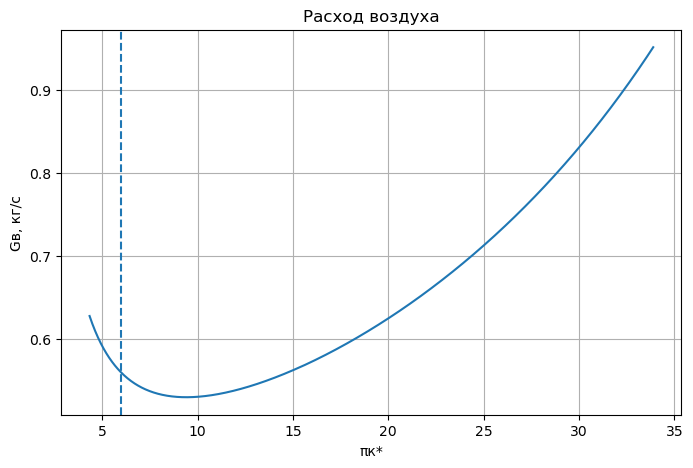

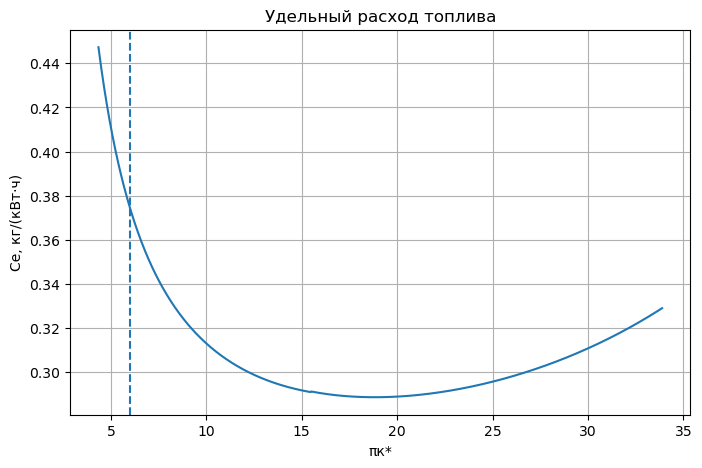

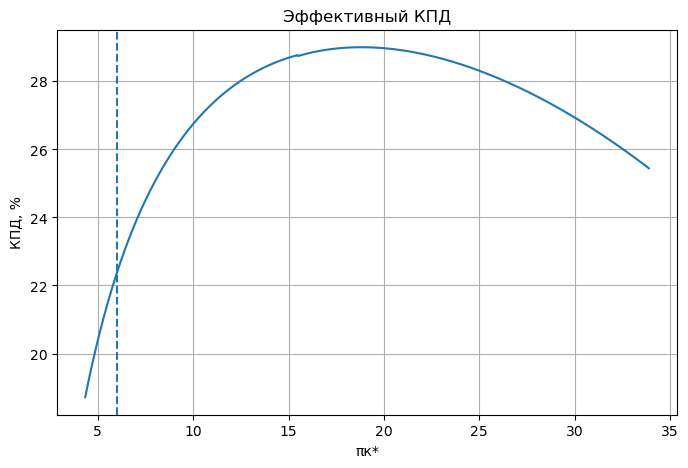

In [50]:
plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['G_air'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Gв, кг/с')
plt.title('Расход воздуха')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['Ce_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Ce, кг/(кВт·ч)')
plt.title('Удельный расход топлива')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], 100*variants['eta_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('КПД, %')
plt.title('Эффективный КПД')
plt.grid()
plt.show()

# Проектирование турбины

## 15. Передача выбранной точки в проектирование
Единственное выбранное πк задаётся в разделе 11 после вариантного расчёта: `pi_k_selected = 6.0`. Таблицы, графики и проектирование турбин используют одну точку. Здесь `pi_k_design` получает уже выбранное значение, а не задаётся независимо.
При изменении πк запускайте все ячейки начиная с раздела 11. Автоматического подбора геометрии при смене точки нет: проверки покажут необходимые изменения.
Источник передачи параметров цикла в расчёт турбины: [1], с. 84, раздел 9, «Задание».


In [51]:
# После расчёта цикла выбираем точку для проектирования турбин
pi_k_design = pi_k_selected  # та же точка, что в таблицах и графиках цикла

if not pi_low <= pi_k_design <= pi_high:
    raise ValueError('Выбранное pi_k_design находится вне рассчитанного диапазона цикла')

design_cycle = cycle(pi_k_design)

print('Точка в исходном разделе цикла:', s['pi_k'])
print('Точка для проектирования турбин:', design_cycle['pi_k'])
print('Мощность, л.с.:', design_cycle['N_shaft'] / HP_TO_KW)
print('Расход газа, кг/с:', round(design_cycle['G_gas'], 5))
print('Температура перед турбиной, К:', design_cycle['Tg'])
display(pd.Series(design_cycle, name='Точка для проектирования').to_frame())

assert s['pi_k'] == design_cycle['pi_k'] == pi_k_selected


Точка в исходном разделе цикла: 6.0
Точка для проектирования турбин: 6.0
Мощность, л.с.: 150.0
Расход газа, кг/с: 0.56867
Температура перед турбиной, К: 1250.0


,Точка для проектирования
pi_k,6.000000
T2,288.000000
p2,99.780500
pi_v,1.000000
M_flight,0.000000
cp_in,1.001282
k_in,1.401802
T3,519.162421
p3,598.683000
L_k,234.571989


## 16. Проектирование при постоянном втулочном диаметре

Принято **D_вт = 90 мм = const** во всей турбинной части: для СА и РК турбины компрессора и силовой турбины. 90 мм — предварительный проектный выбор; меняется в одной ячейке ниже.

В отличие от прежней схемы средний диаметр не постоянен: D1=D_вт+l_СА, D2=D_вт+l_РК. Окружные скорости на среднем радиусе входа и выхода РК различаются. Поэтому пересчитаны треугольники и работа по уравнению Эйлера.

Сохраняются πк=6, 150 л.с., одна силовая ступень, простые последовательные присваивания. H0 и параметры СТ уточнены по требуемой работе, c2=250 м/с и α2=87°. В коде указаны явные входные числа; скрытого автоподбора при изменении исходных нет.

Это предварительная одномерная модель по средним сечениям. Потери и их коэффициенты сохранены; меридиональная скорость приближённо считается осевой. Эмпирический параметр ρ распределяет заданный теплоперепад, а не заменяет уточнение пространственной реактивности.

Единицы: T — К, p — кПа, cp — кДж/(кг·К), H и L — кДж/кг, размеры — м, n — об/мин. Источники исходной модели: [1] §9, с. 84–93; [2] «цикл.pdf», приложение 6. Расширение на u1≠u2 основано на уравнении Эйлера и сохранении ротальпии: [NASA turbo-design](https://github.com/nasa/turbo-design/blob/main/entropy_based_efficiency.md).

In [16]:
# Данные выбранного цикла
G_gas_design = design_cycle['G_gas']
alpha_design = design_cycle['alpha']
L_tk_required = design_cycle['L_gg']
L_st_required = design_cycle['L_pt']

phi = 0.97
psi = 0.96
relative_gap = 0.008
partial_admission = 1.0
kn = 6.8e-6
sigma_limit = 200.0  # Предварительный допуск: материал и ресурс не обоснованы

# Явные теплоперепады, согласованные по работе для pi_k=6
H0_tk = 280.42999742338185
H0_st = 254.79158253044633

rho_tk = 0.30
alpha1_tk = 18.0
kappa_tk = 1.10

# Одна силовая ступень воспринимает всю требуемую работу СТ
n_st = 71822.79812564902
rho_st = 0.35
alpha1_st = 23.988401246855695
kappa_st = 1.1

print('Выбранное pi_k:', design_cycle['pi_k'])
print('Число ступеней силовой турбины: 1')
print('Расход газа, кг/с:', round(G_gas_design, 5))
if g_cool != 0:
    raise ValueError('Для охлаждаемой турбины нужен отдельный баланс смешения.')

# Единый втулочный диаметр всей турбинной части, м (предварительный выбор)
D_hub = 0.090

speed_fraction_tk = 0.8501078522588451


Выбранное pi_k: 6.0
Число ступеней силовой турбины: 1
Расход газа, кг/с: 0.56867


### 16.1. Предварительная частота ТК

По прежней оценке площади и допускаемого напряжения выбираем частоту:
$$H_{оц}=(L_{ТК}+c_a^2/2000)/\eta_{л,оц},\quad
T_{оц}=T_0-H_{оц}\eta_{л,оц}/c_{p0},$$
$$p_{оц}=p_0[1-H_{оц}/(c_{p0}T_0)]^{k_0/(k_0-1)},\quad
A_{оц}=GR_gT_{оц}/(p_{оц}c_a),$$
$$n_{max}=\sqrt{\sigma_{доп}/(k_nA_{оц})},\quad n=f_n n_{max}.$$
Источник оценки предельной частоты: [1], с. 85–86. Доля f_n задана в разделе 16; частота и H0 уточнены по работе ТК и пробному выходному углу 87°. Средние диаметры теперь определяются по постоянному D втулки и проходным площадям, а не по выбранной окружной скорости.

In [17]:
T0_tk = design_cycle['Tg']
p0_tk = design_cycle['pg']
cp0_tk = cp_i(T0_tk, alpha_design)
k0_tk = cp0_tk / (cp0_tk - R_gas)

c_axial_est = 200.0
eta_blade_est = 0.90
H_est = (L_tk_required + c_axial_est**2 / 2000) / eta_blade_est
T_est = T0_tk - H_est * eta_blade_est / cp0_tk
p_est = p0_tk * (1 - H_est / (cp0_tk * T0_tk))**(k0_tk / (k0_tk - 1))
v_est = R_gas * T_est / p_est
A_est = G_gas_design * v_est / c_axial_est

n_max_est = math.sqrt(sigma_limit / (kn * A_est))
n_tk = speed_fraction_tk * n_max_est

print('n ТК, об/мин:', round(n_tk))
print('D втулки, мм:', D_hub*1000)


n ТК, об/мин: 77829
D втулки, мм: 90.0


## 17. Турбина компрессора

Все переменные этого раздела имеют суффикс `_tk`. Втулочный диаметр постоянен; средние диаметры на входе и выходе РК различаются.


**А. Свойства газа**
$$T_y=T_0-\frac{H_0\varphi^2}{2c_p},\qquad c_p=c_{pi}(T_y,\alpha),\qquad k=\frac{c_p}{c_p-R_g}.$$
Короткий цикл уточняет только теплоёмкость. Источник: [1], с. 88, п. 75–76; функция `cp_i` определена в расчёте цикла.


In [18]:
cp_tk = cp_i(T0_tk, alpha_design)
for i in range(20):
    T_mean_tk = T0_tk - H0_tk * phi**2 / (2 * cp_tk)
    cp_tk = cp_i(T_mean_tk, alpha_design)
k_tk = cp_tk / (cp_tk - R_gas)


**Б. Сопловой аппарат**
$$H_c=H_0(1-\rho),\quad c_1=\varphi\sqrt{2000H_c},\quad
T_1=T_0-\frac{H_c\varphi^2}{c_p},\quad T_1'=T_0-\frac{H_c}{c_p},$$
$$p_1=p_0(T_1'/T_0)^{k/(k-1)},\quad v_1=R_gT_1/p_1,\quad
l_c=\frac{Gv_1}{\pi Dc_1\sin\alpha_1},$$
$$A_1=\pi Dl_c,\qquad c_{1a}=Gv_1/A_1,\qquad c_{1u}=c_1\cos\alpha_1.$$
Источник: [1], с. 88–89, п. 63, 72–83. `l_stator` — высота сопловой лопатки; `T1_ad` — $T_1'$. Углы в исходных данных указаны в градусах, в `sin` и `cos` передаются радианы.


**Геометрия при D_вт=const (вместо формулы с заранее заданным D):**
$$c_{1a}=c_1\sin\alpha_1,\quad A_1=Gv_1/c_{1a},$$
$$l_1=\frac{\sqrt{D_{вт}^2+4A_1/\pi}-D_{вт}}2,\quad D_1=D_{вт}+l_1.$$
Это преобразование площади кольца A=π(D_вт+l)l. Старое выражение l=Gv/(πDc_a) эквивалентно ему, но D теперь неизвестен заранее.

In [19]:
angle1_tk = math.radians(alpha1_tk)
Hc_tk = H0_tk * (1 - rho_tk)
c1_tk = phi * math.sqrt(2000 * Hc_tk)
T1_tk = T0_tk - Hc_tk * phi**2 / cp_tk
T1_ad_tk = T0_tk - Hc_tk / cp_tk
p1_tk = p0_tk * (T1_ad_tk / T0_tk)**(k_tk / (k_tk - 1))
v1_tk = R_gas * T1_tk / p1_tk

c1a_tk = c1_tk * math.sin(angle1_tk)
c1u_tk = c1_tk * math.cos(angle1_tk)
A1_tk = G_gas_design * v1_tk / c1a_tk
l_stator_tk = (math.sqrt(D_hub**2 + 4*A1_tk/math.pi) - D_hub) / 2
D1_tk = D_hub + l_stator_tk


**В. Рабочее колесо при разных средних радиусах**
$$u_1=\pi D_1n/60,\quad w_1^2=c_1^2+u_1^2-2c_1u_1\cos\alpha_1,$$
$$\beta_1=\operatorname{atan2}(c_{1a},c_{1u}-u_1),\quad
H_l=\rho H_0T_1/T_1',\quad T_2'=T_1-H_l/c_p,\quad
p_2=p_1(T_2'/T_1)^{k/(k-1)}.$$
Высота выхода уточняется коротким циклом неразрывности:
$$D_2=D_{вт}+l_2,\quad u_2=\pi D_2n/60,$$
$$w_2=\psi\sqrt{w_1^2+2000H_l+u_2^2-u_1^2},$$
$$T_2=T_1+\frac{u_2^2-u_1^2-w_2^2+w_1^2}{2000c_p},\quad v_2=R_gT_2/p_2,$$
$$c_{2a}=\kappa c_{1a},\quad A_2=Gv_2/c_{2a},\quad
l_2=\frac{\sqrt{D_{вт}^2+4A_2/\pi}-D_{вт}}2.$$
После сходимости:
$$\beta_2=\arcsin(c_{2a}/w_2),\quad c_{2u}=w_2\cos\beta_2-u_2,$$
$$\alpha_2=\operatorname{atan2}(c_{2a},c_{2u}),\quad c_2^2=c_{2a}^2+c_{2u}^2.$$
В принятой знаковой записи c2u направлена против вращения. Добавки u2²−u1² следуют из сохранения ротальпии h+(w²−u²)/2=const; это расширение прежних формул постоянного среднего диаметра, а не дословная формула [1]. При u1=u2 они обращаются в прежний вариант. Модель потерь ψ сохранена как предварительное приближение.

In [20]:
# Средние диаметры на входе и выходе РК различаются.
u1_tk = math.pi * D1_tk * n_tk / 60
w1_tk = math.sqrt(c1_tk**2 + u1_tk**2 - 2*c1_tk*u1_tk*math.cos(angle1_tk))
beta1_tk = math.degrees(math.atan2(c1a_tk, c1u_tk - u1_tk))
Hl_tk = rho_tk * H0_tk * T1_tk / T1_ad_tk
T2_ad_tk = T1_tk - Hl_tk/cp_tk
p2_tk = p1_tk * (T2_ad_tk/T1_tk)**(k_tk/(k_tk-1))
c2a_tk = kappa_tk * c1a_tk

# Уточняем высоту из неразрывности: она меняет D2 и u2.
l_rotor_tk = l_stator_tk
for i in range(60):
    D2_tk = D_hub + l_rotor_tk
    u2_tk = math.pi * D2_tk * n_tk / 60
    w2_tk = psi * math.sqrt(w1_tk**2 + 2000*Hl_tk + u2_tk**2 - u1_tk**2)
    T2_tk = T1_tk + (u2_tk**2-u1_tk**2-w2_tk**2+w1_tk**2)/(2000*cp_tk)
    v2_tk = R_gas * T2_tk/p2_tk
    A2_tk = G_gas_design * v2_tk/c2a_tk
    l_new_tk = (math.sqrt(D_hub**2 + 4*A2_tk/math.pi) - D_hub)/2
    if abs(l_new_tk - l_rotor_tk) < 1e-14:
        break
    l_rotor_tk = l_new_tk
else:
    raise ValueError('Не сошлась геометрия РК tk')

beta2_tk = math.degrees(math.asin(c2a_tk/w2_tk))
c2u_tk = w2_tk*math.cos(math.radians(beta2_tk)) - u2_tk
alpha2_tk = math.degrees(math.atan2(c2a_tk, c2u_tk))
c2_tk = math.sqrt(c2a_tk**2+c2u_tk**2)
D_tk = D2_tk  # Средний диаметр на выходе РК для таблиц и потерь
u_tk = u2_tk


**Г. Работа, потери и КПД**
$$L_u=(u_1c_{1u}+u_2c_{2u})/1000,\qquad\eta_u=L_u/H_0,$$
$$h_c=(\varphi^{-2}-1)c_1^2/2000,\quad h_l=(\psi^{-2}-1)w_2^2/2000,\quad h_v=c_2^2/2000,$$
$$\delta=\delta_{rel}l_l,\quad
h_z=1.37(1+1.6\rho)(1+l_l/D)(\delta/l_l)L_u,$$
$$\bar\rho_g=(1/v_1+1/v_2)/2,\quad
N_{тв}=[1.07D^2+61(1-\varepsilon)Dl_l](u/100)^3\bar\rho_g,\quad h_{тв}=N_{тв}/G,$$
$$\eta_t=\eta_u-(h_z+h_{тв})/H_0,\qquad L_t=H_0\eta_t.$$
Источник: [1], с. 90–91, п. 101–124; эмпирическая формула трения с единицами — с. 44. Она даёт $N_{тв}$ в кВт; все удельные потери здесь в кДж/кг. `eta_power` — мощностной КПД по полному входному и статическому выходному давлению, а не полный КПД.


В оценке зазора и трения D=D2, u=u2. Это сохранённое предварительное замыкание модели потерь для изменяющегося среднего диаметра.

In [21]:
Lu_tk = (u1_tk * c1u_tk + u2_tk * c2u_tk) / 1000
eta_u_tk = Lu_tk / H0_tk
hc_tk = (1 / phi**2 - 1) * c1_tk**2 / 2000
hl_tk = (1 / psi**2 - 1) * w2_tk**2 / 2000
hv_tk = c2_tk**2 / 2000

clearance_tk = relative_gap * l_rotor_tk
hz_tk = 1.37 * (1 + 1.6 * rho_tk) * (1 + l_rotor_tk / D_tk) * clearance_tk / l_rotor_tk * Lu_tk
density_tk = (1 / v1_tk + 1 / v2_tk) / 2
N_friction_tk = (1.07 * D_tk**2 + 61 * (1 - partial_admission) * D_tk * l_rotor_tk) * (u_tk / 100)**3 * density_tk
h_friction_tk = N_friction_tk / G_gas_design

eta_power_tk = eta_u_tk - (hz_tk + h_friction_tk) / H0_tk
eta_blade_tk = eta_power_tk + hv_tk / H0_tk
L_tk = H0_tk * eta_power_tk


**Д. Выходные параметры и полный КПД**
$$T_{ст}=T_2+(h_z+h_{тв})/c_p,\quad T_{out}^*=T_{ст}+h_v/c_p,$$
$$p_{out}^*=p_2(T_{out}^*/T_{ст})^{k/(k-1)},\quad
H_0^*=c_pT_0[1-(p_{out}^*/p_0)^{(k-1)/k}],\quad\eta_t^*=L_t/H_0^*.$$
Источник: [1], с. 91, п. 125–129. Звёздочка — полные параметры; `T_exit` и `p2` — статические, `T_out_total` и `p_out_total` — полные.


In [22]:
T_exit_tk = T2_tk + (hz_tk + h_friction_tk) / cp_tk
T_out_total_tk = T_exit_tk + hv_tk / cp_tk
p_out_total_tk = p2_tk * (T_out_total_tk / T_exit_tk)**(k_tk / (k_tk - 1))
H_total_tk = cp_tk * T0_tk * (1 - (p_out_total_tk / p0_tk)**((k_tk - 1) / k_tk))
eta_total_tk = L_tk / H_total_tk


**Е. Предварительные контрольные величины**
$$\sigma_l=k_nn^2A_2,\quad M_1=\frac{c_1}{\sqrt{1000kR_gT_1}},\quad
M_{w2}=\frac{w_2}{\sqrt{1000kR_gT_2}},\quad l_l/D.$$

Оценка у корня при $\alpha_1=const$:
$$r_m=D/2,\quad r_k=r_m-l_c/2,\quad c_{1k}=c_1(r_m/r_k)^{\cos^2\alpha_1},$$
$$p_{1k}=p_0\left[1-\frac{(c_{1k}/\varphi)^2}{2000c_pT_0}\right]^{k/(k-1)},\quad
T_{1k}'=T_0(p_{1k}/p_0)^{(k-1)/k},$$
$$\rho_k=\frac{c_pT_{1k}'}{H_0}\left[1-(p_2/p_{1k})^{(k-1)/k}\right].$$
Источник: [1], с. 55, (63), с. 58, §7.3; оценка корня — та же, что в предыдущем ноутбуке и присланной функции `ρ_корня`. Она не заменяет полного профилирования.


Для оценки у корня СА берётся r_m=D1/2, r_k=D_вт/2; отношение l/D и напряжение оцениваются по выходу РК (D2).

In [23]:
sigma_tk = kn * n_tk**2 * A2_tk
M1_tk = c1_tk / math.sqrt(1000 * k_tk * R_gas * T1_tk)
M2_relative_tk = w2_tk / math.sqrt(1000 * k_tk * R_gas * T2_tk)
blade_ratio_tk = l_rotor_tk / D_tk

r_mean_tk = D1_tk / 2
r_root_tk = r_mean_tk - l_stator_tk / 2
c1_root_tk = c1_tk * (r_mean_tk / r_root_tk)**(math.cos(angle1_tk)**2)
p1_root_tk = p0_tk * (1 - (c1_root_tk / phi)**2 / (2000 * cp_tk * T0_tk))**(k_tk / (k_tk - 1))
T1_root_ad_tk = T0_tk * (p1_root_tk / p0_tk)**((k_tk - 1) / k_tk)
rho_root_tk = cp_tk * T1_root_ad_tk / H0_tk * (1 - (p2_tk / p1_root_tk)**((k_tk - 1) / k_tk))


## 18. Силовая турбина — одна ступень

Все переменные имеют суффикс `_st`. Втулочный диаметр постоянен; средние диаметры на входе и выходе РК различаются.

**Вход силовой ступени** — выход турбины компрессора:
$$T_{0,СТ}=T_{out,ТК}^*,\qquad p_{0,СТ}=p_{out,ТК}^*.$$
Потери межтурбинного перехода пока не заданы. Это принятое замыкание тракта; отдельный расчёт перехода ещё нужен.

In [24]:
T0_st = T_out_total_tk
p0_st = p_out_total_tk


**А. Свойства газа**
$$T_y=T_0-\frac{H_0\varphi^2}{2c_p},\qquad c_p=c_{pi}(T_y,\alpha),\qquad k=\frac{c_p}{c_p-R_g}.$$
Короткий цикл уточняет только теплоёмкость. Источник: [1], с. 88, п. 75–76; функция `cp_i` определена в расчёте цикла.


In [25]:
cp_st = cp_i(T0_st, alpha_design)
for i in range(20):
    T_mean_st = T0_st - H0_st * phi**2 / (2 * cp_st)
    cp_st = cp_i(T_mean_st, alpha_design)
k_st = cp_st / (cp_st - R_gas)


**Б. Сопловой аппарат**
$$H_c=H_0(1-\rho),\quad c_1=\varphi\sqrt{2000H_c},\quad
T_1=T_0-\frac{H_c\varphi^2}{c_p},\quad T_1'=T_0-\frac{H_c}{c_p},$$
$$p_1=p_0(T_1'/T_0)^{k/(k-1)},\quad v_1=R_gT_1/p_1,\quad
l_c=\frac{Gv_1}{\pi Dc_1\sin\alpha_1},$$
$$A_1=\pi Dl_c,\qquad c_{1a}=Gv_1/A_1,\qquad c_{1u}=c_1\cos\alpha_1.$$
Источник: [1], с. 88–89, п. 63, 72–83. `l_stator` — высота сопловой лопатки; `T1_ad` — $T_1'$. Углы в исходных данных указаны в градусах, в `sin` и `cos` передаются радианы.


**Геометрия при D_вт=const (вместо формулы с заранее заданным D):**
$$c_{1a}=c_1\sin\alpha_1,\quad A_1=Gv_1/c_{1a},$$
$$l_1=\frac{\sqrt{D_{вт}^2+4A_1/\pi}-D_{вт}}2,\quad D_1=D_{вт}+l_1.$$
Это преобразование площади кольца A=π(D_вт+l)l. Старое выражение l=Gv/(πDc_a) эквивалентно ему, но D теперь неизвестен заранее.

In [26]:
angle1_st = math.radians(alpha1_st)
Hc_st = H0_st * (1 - rho_st)
c1_st = phi * math.sqrt(2000 * Hc_st)
T1_st = T0_st - Hc_st * phi**2 / cp_st
T1_ad_st = T0_st - Hc_st / cp_st
p1_st = p0_st * (T1_ad_st / T0_st)**(k_st / (k_st - 1))
v1_st = R_gas * T1_st / p1_st

c1a_st = c1_st * math.sin(angle1_st)
c1u_st = c1_st * math.cos(angle1_st)
A1_st = G_gas_design * v1_st / c1a_st
l_stator_st = (math.sqrt(D_hub**2 + 4*A1_st/math.pi) - D_hub) / 2
D1_st = D_hub + l_stator_st


**В. Рабочее колесо при разных средних радиусах**
$$u_1=\pi D_1n/60,\quad w_1^2=c_1^2+u_1^2-2c_1u_1\cos\alpha_1,$$
$$\beta_1=\operatorname{atan2}(c_{1a},c_{1u}-u_1),\quad
H_l=\rho H_0T_1/T_1',\quad T_2'=T_1-H_l/c_p,\quad
p_2=p_1(T_2'/T_1)^{k/(k-1)}.$$
Высота выхода уточняется коротким циклом неразрывности:
$$D_2=D_{вт}+l_2,\quad u_2=\pi D_2n/60,$$
$$w_2=\psi\sqrt{w_1^2+2000H_l+u_2^2-u_1^2},$$
$$T_2=T_1+\frac{u_2^2-u_1^2-w_2^2+w_1^2}{2000c_p},\quad v_2=R_gT_2/p_2,$$
$$c_{2a}=\kappa c_{1a},\quad A_2=Gv_2/c_{2a},\quad
l_2=\frac{\sqrt{D_{вт}^2+4A_2/\pi}-D_{вт}}2.$$
После сходимости:
$$\beta_2=\arcsin(c_{2a}/w_2),\quad c_{2u}=w_2\cos\beta_2-u_2,$$
$$\alpha_2=\operatorname{atan2}(c_{2a},c_{2u}),\quad c_2^2=c_{2a}^2+c_{2u}^2.$$
В принятой знаковой записи c2u направлена против вращения. Добавки u2²−u1² следуют из сохранения ротальпии h+(w²−u²)/2=const; это расширение прежних формул постоянного среднего диаметра, а не дословная формула [1]. При u1=u2 они обращаются в прежний вариант. Модель потерь ψ сохранена как предварительное приближение.

In [27]:
# Средние диаметры на входе и выходе РК различаются.
u1_st = math.pi * D1_st * n_st / 60
w1_st = math.sqrt(c1_st**2 + u1_st**2 - 2*c1_st*u1_st*math.cos(angle1_st))
beta1_st = math.degrees(math.atan2(c1a_st, c1u_st - u1_st))
Hl_st = rho_st * H0_st * T1_st / T1_ad_st
T2_ad_st = T1_st - Hl_st/cp_st
p2_st = p1_st * (T2_ad_st/T1_st)**(k_st/(k_st-1))
c2a_st = kappa_st * c1a_st

# Уточняем высоту из неразрывности: она меняет D2 и u2.
l_rotor_st = l_stator_st
for i in range(60):
    D2_st = D_hub + l_rotor_st
    u2_st = math.pi * D2_st * n_st / 60
    w2_st = psi * math.sqrt(w1_st**2 + 2000*Hl_st + u2_st**2 - u1_st**2)
    T2_st = T1_st + (u2_st**2-u1_st**2-w2_st**2+w1_st**2)/(2000*cp_st)
    v2_st = R_gas * T2_st/p2_st
    A2_st = G_gas_design * v2_st/c2a_st
    l_new_st = (math.sqrt(D_hub**2 + 4*A2_st/math.pi) - D_hub)/2
    if abs(l_new_st - l_rotor_st) < 1e-14:
        break
    l_rotor_st = l_new_st
else:
    raise ValueError('Не сошлась геометрия РК st')

beta2_st = math.degrees(math.asin(c2a_st/w2_st))
c2u_st = w2_st*math.cos(math.radians(beta2_st)) - u2_st
alpha2_st = math.degrees(math.atan2(c2a_st, c2u_st))
c2_st = math.sqrt(c2a_st**2+c2u_st**2)
D_st = D2_st  # Средний диаметр на выходе РК для таблиц и потерь
u_st = u2_st


**Г. Работа, потери и КПД**
$$L_u=(u_1c_{1u}+u_2c_{2u})/1000,\qquad\eta_u=L_u/H_0,$$
$$h_c=(\varphi^{-2}-1)c_1^2/2000,\quad h_l=(\psi^{-2}-1)w_2^2/2000,\quad h_v=c_2^2/2000,$$
$$\delta=\delta_{rel}l_l,\quad
h_z=1.37(1+1.6\rho)(1+l_l/D)(\delta/l_l)L_u,$$
$$\bar\rho_g=(1/v_1+1/v_2)/2,\quad
N_{тв}=[1.07D^2+61(1-\varepsilon)Dl_l](u/100)^3\bar\rho_g,\quad h_{тв}=N_{тв}/G,$$
$$\eta_t=\eta_u-(h_z+h_{тв})/H_0,\qquad L_t=H_0\eta_t.$$
Источник: [1], с. 90–91, п. 101–124; эмпирическая формула трения с единицами — с. 44. Она даёт $N_{тв}$ в кВт; все удельные потери здесь в кДж/кг. `eta_power` — мощностной КПД по полному входному и статическому выходному давлению, а не полный КПД.


В оценке зазора и трения D=D2, u=u2. Это сохранённое предварительное замыкание модели потерь для изменяющегося среднего диаметра.

In [28]:
Lu_st = (u1_st * c1u_st + u2_st * c2u_st) / 1000
eta_u_st = Lu_st / H0_st
hc_st = (1 / phi**2 - 1) * c1_st**2 / 2000
hl_st = (1 / psi**2 - 1) * w2_st**2 / 2000
hv_st = c2_st**2 / 2000

clearance_st = relative_gap * l_rotor_st
hz_st = 1.37 * (1 + 1.6 * rho_st) * (1 + l_rotor_st / D_st) * clearance_st / l_rotor_st * Lu_st
density_st = (1 / v1_st + 1 / v2_st) / 2
N_friction_st = (1.07 * D_st**2 + 61 * (1 - partial_admission) * D_st * l_rotor_st) * (u_st / 100)**3 * density_st
h_friction_st = N_friction_st / G_gas_design

eta_power_st = eta_u_st - (hz_st + h_friction_st) / H0_st
eta_blade_st = eta_power_st + hv_st / H0_st
L_st = H0_st * eta_power_st


**Д. Выходные параметры и полный КПД**
$$T_{ст}=T_2+(h_z+h_{тв})/c_p,\quad T_{out}^*=T_{ст}+h_v/c_p,$$
$$p_{out}^*=p_2(T_{out}^*/T_{ст})^{k/(k-1)},\quad
H_0^*=c_pT_0[1-(p_{out}^*/p_0)^{(k-1)/k}],\quad\eta_t^*=L_t/H_0^*.$$
Источник: [1], с. 91, п. 125–129. Звёздочка — полные параметры; `T_exit` и `p2` — статические, `T_out_total` и `p_out_total` — полные.


In [29]:
T_exit_st = T2_st + (hz_st + h_friction_st) / cp_st
T_out_total_st = T_exit_st + hv_st / cp_st
p_out_total_st = p2_st * (T_out_total_st / T_exit_st)**(k_st / (k_st - 1))
H_total_st = cp_st * T0_st * (1 - (p_out_total_st / p0_st)**((k_st - 1) / k_st))
eta_total_st = L_st / H_total_st


**Е. Предварительные контрольные величины**
$$\sigma_l=k_nn^2A_2,\quad M_1=\frac{c_1}{\sqrt{1000kR_gT_1}},\quad
M_{w2}=\frac{w_2}{\sqrt{1000kR_gT_2}},\quad l_l/D.$$

Оценка у корня при $\alpha_1=const$:
$$r_m=D/2,\quad r_k=r_m-l_c/2,\quad c_{1k}=c_1(r_m/r_k)^{\cos^2\alpha_1},$$
$$p_{1k}=p_0\left[1-\frac{(c_{1k}/\varphi)^2}{2000c_pT_0}\right]^{k/(k-1)},\quad
T_{1k}'=T_0(p_{1k}/p_0)^{(k-1)/k},$$
$$\rho_k=\frac{c_pT_{1k}'}{H_0}\left[1-(p_2/p_{1k})^{(k-1)/k}\right].$$
Источник: [1], с. 55, (63), с. 58, §7.3; оценка корня — та же, что в предыдущем ноутбуке и присланной функции `ρ_корня`. Она не заменяет полного профилирования.


Для оценки у корня СА берётся r_m=D1/2, r_k=D_вт/2; отношение l/D и напряжение оцениваются по выходу РК (D2).

In [30]:
sigma_st = kn * n_st**2 * A2_st
M1_st = c1_st / math.sqrt(1000 * k_st * R_gas * T1_st)
M2_relative_st = w2_st / math.sqrt(1000 * k_st * R_gas * T2_st)
blade_ratio_st = l_rotor_st / D_st

r_mean_st = D1_st / 2
r_root_st = r_mean_st - l_stator_st / 2
c1_root_st = c1_st * (r_mean_st / r_root_st)**(math.cos(angle1_st)**2)
p1_root_st = p0_st * (1 - (c1_root_st / phi)**2 / (2000 * cp_st * T0_st))**(k_st / (k_st - 1))
T1_root_ad_st = T0_st * (p1_root_st / p0_st)**((k_st - 1) / k_st)
rho_root_st = cp_st * T1_root_ad_st / H0_st * (1 - (p2_st / p1_root_st)**((k_st - 1) / k_st))


## 19. Сводная таблица и балансы

$$N_{ТК}=GL_{ТК}\eta_{m,ГГ},\qquad N_{вал}=GL_{СТ}\eta_{m,СТ}\eta_r.$$
Вся работа силовой турбины выполняется одной ступенью. Полный КПД СТ равен полному КПД этой ступени. Требуемая работа берётся из цикла независимо от расчёта ступени.

Проверяем фактические невязки работ и мощностей. При изменении параметров уточняйте явные H0 в разделе 16. Источник: [1], с. 93, п. 146–153.

In [31]:
N_tk = G_gas_design * L_tk * eta_m_gg
N_compressor = design_cycle['G_air'] * design_cycle['L_k']
N_shaft = G_gas_design * L_st * eta_m_pt * eta_red

cp_st_mean = cp_i((T0_st + T_out_total_st) / 2, alpha_design)
k_st_mean = cp_st_mean / (cp_st_mean - R_gas)
H_st_total = cp_st_mean * T0_st * (1 - (p_out_total_st / p0_st)**((k_st_mean - 1) / k_st_mean))
eta_st_total = L_st / H_st_total

stage_table = pd.DataFrame([
    ['ТК', n_tk, D1_tk*1000, D2_tk*1000, D_hub*1000, l_stator_tk*1000, l_rotor_tk*1000, L_tk, eta_total_tk*100, alpha2_tk, M1_tk, sigma_tk],
    ['СТ', n_st, D1_st*1000, D2_st*1000, D_hub*1000, l_stator_st*1000, l_rotor_st*1000, L_st, eta_total_st*100, alpha2_st, M1_st, sigma_st],
], columns=['Ступень', 'n, об/мин', 'D1 средний, мм', 'D2 средний, мм', 'D втулки, мм', 'СА, мм', 'РК, мм', 'L, кДж/кг', 'КПД полный, %', 'alpha2, град', 'M за СА', 'sigma, МПа'])
display(stage_table.round(4))

power_balance = pd.DataFrame([
    ['Первый вал', N_tk, N_compressor, N_tk - N_compressor],
    ['Выходной вал', N_shaft, power_kw, N_shaft - power_kw]
], columns=['Проверка', 'Расчёт, кВт', 'Требуется, кВт', 'Невязка, кВт'])
display(power_balance)

work_balance = pd.DataFrame([
    ['ТК', L_tk, L_tk_required, L_tk - L_tk_required],
    ['СТ', L_st, L_st_required, L_st - L_st_required],
], columns=['Ступень', 'Работа, кДж/кг', 'Требуется, кДж/кг', 'Невязка, кДж/кг'])
display(work_balance)
print('Мощность после редуктора, л.с.:', round(N_shaft / HP_TO_KW, 3))
print('Полный КПД силовой турбины, %:', round(eta_st_total * 100, 3))

,Ступень,"n, об/мин","D1 средний, мм","D2 средний, мм","D втулки, мм","СА, мм","РК, мм","L, кДж/кг","КПД полный, %","alpha2, град",M за СА,"sigma, МПа"
0,ТК,77828.5598,99.5013,100.6310,90.0,9.5013,10.6310,233.3292,89.9260,87.0,0.9437,138.4334
1,СТ,71822.7981,103.9713,106.3648,90.0,13.9713,16.3648,199.9632,89.1605,87.0,0.9398,191.8191


,Проверка,"Расчёт, кВт","Требуется, кВт","Невязка, кВт"
0,Первый вал,131.360889,131.360889,4.280309e-11
1,Выходной вал,110.324812,110.324812,0.000000e+00


,Ступень,"Работа, кДж/кг","Требуется, кДж/кг","Невязка, кДж/кг"
0,ТК,233.329215,233.329215,7.605649e-11
1,СТ,199.963240,199.963240,0.000000e+00


Мощность после редуктора, л.с.: 150.0
Полный КПД силовой турбины, %: 89.133


## 20. Открытые проверки ограничений

$\Delta p=p_{расч}^*/p_{цикл}^*-1$. Порог 1% по давлению и прежняя цель высоты РК СТ ≥20 мм — выбранные критерии, не нормативы книги. Для единственной (последней) ступени СТ проверяем угол 80–90°. Источник: [1], с. 38, 55–58 и п. 99.

Невыполненные проверки остаются видимыми. Согласование по мощности не означает согласования по давлению. Допуск 200 МПа предварительный; прочность дисков, вибрации, материал и ресурс не рассчитаны.

In [32]:
dp_tk = p_out_total_tk / design_cycle['p4'] - 1
dp_st = p_out_total_st / design_cycle['p5_total'] - 1
dp_st_static = p2_st / design_cycle['p5'] - 1
dc_st = c2_st / c_pt_exit - 1

checks = pd.DataFrame([
    ['ТК: угол выхода', alpha2_tk, 80 <= alpha2_tk <= 90],
    ['СТ: угол выхода', alpha2_st, 80 <= alpha2_st <= 90],
    ['ТК: напряжение, МПа', sigma_tk, sigma_tk <= sigma_limit],
    ['СТ: напряжение, МПа', sigma_st, sigma_st <= sigma_limit],
    ['ТК: l/D', blade_ratio_tk, 0 < blade_ratio_tk <= 1/3],
    ['СТ: l/D', blade_ratio_st, 0 < blade_ratio_st <= 1/3],
    ['ТК: реактивность у корня', rho_root_tk, rho_root_tk >= 0.05],
    ['СТ: реактивность у корня', rho_root_st, rho_root_st >= 0.05],
    ['ТК: M за СА', M1_tk, M1_tk <= 1],
    ['СТ: M за СА', M1_st, M1_st <= 1],
    ['ТК: M отн. за РК', M2_relative_tk, M2_relative_tk <= 1],
    ['СТ: M отн. за РК', M2_relative_st, M2_relative_st <= 1],
    ['СТ: высота РК, мм', l_rotor_st*1000, l_rotor_st >= 0.020],
    ['ТК: полное давление, отличие %', dp_tk*100, abs(dp_tk) < 0.01],
    ['СТ: полное давление, отличие %', dp_st*100, abs(dp_st) < 0.01],
    ['СТ: статическое давление, отличие %', dp_st_static*100, abs(dp_st_static) < 0.01],
    ['СТ: скорость выхода, отличие %', dc_st*100, abs(dc_st) < 0.01],
    ['Первый вал: баланс, кВт', N_tk - N_compressor, abs(N_tk - N_compressor) < 1e-6],
    ['Выходной вал: баланс, кВт', N_shaft - power_kw, abs(N_shaft - power_kw) < 1e-6]
], columns=['Проверка', 'Значение', 'Выполнено'])
display(checks)
hub_diameters = np.array([D1_tk-l_stator_tk, D2_tk-l_rotor_tk,
                          D1_st-l_stator_st, D2_st-l_rotor_st])
print('Втулочные диаметры четырёх сечений, мм:', hub_diameters*1000)
assert np.allclose(hub_diameters, D_hub, rtol=0, atol=1e-12)
for D2, height, v2, ca2 in [(D2_tk,l_rotor_tk,v2_tk,c2a_tk), (D2_st,l_rotor_st,v2_st,c2a_st)]:
    assert abs(math.pi*D2*height*ca2/v2 - G_gas_design) < 1e-9


,Проверка,Значение,Выполнено
0,ТК: угол выхода,8.700000e+01,True
1,СТ: угол выхода,8.700000e+01,True
2,"ТК: напряжение, МПа",1.384334e+02,True
3,"СТ: напряжение, МПа",1.918191e+02,True
4,ТК: l/D,1.056430e-01,True
5,СТ: l/D,1.538553e-01,True
6,ТК: реактивность у корня,1.606435e-01,True
7,СТ: реактивность у корня,1.729383e-01,True
8,ТК: M за СА,9.436620e-01,True
9,СТ: M за СА,9.397968e-01,True


Втулочные диаметры четырёх сечений, мм: [90. 90. 90. 90.]


## 21. Высоты лопаток

Высоты пера СА и РК турбины компрессора и единственной силовой ступени, без хвостовиков.

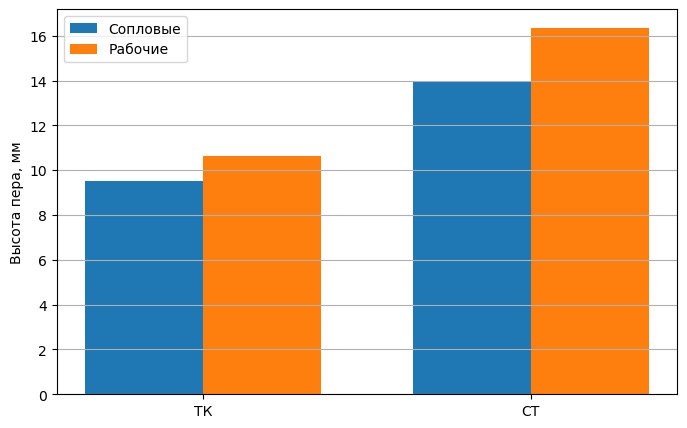

In [33]:
stage_names = ['ТК', 'СТ']
stator_heights = np.array([l_stator_tk, l_stator_st]) * 1000
rotor_heights = np.array([l_rotor_tk, l_rotor_st]) * 1000
x_bars = np.array([0, 1])
plt.figure(figsize=(8, 5))
plt.bar(x_bars - 0.18, stator_heights, width=0.36, label='Сопловые')
plt.bar(x_bars + 0.18, rotor_heights, width=0.36, label='Рабочие')
plt.xticks(x_bars, stage_names)
plt.ylabel('Высота пера, мм')
plt.grid(axis='y')
plt.legend()
plt.show()


## 22. Предварительная проточная часть: радиусы, верхняя половина

По Y — радиусы в миллиметрах; y=0 — ось симметрии, показана только верхняя половина.
$$r_{ср}=D/2,\qquad r_{нар}=(D+l)/2,\qquad r_{вт}=(D-l)/2.$$
Расстояние между контурами равно высоте пера l. Четыре сечения: выход СА ТК, выход РК ТК, выход СА СТ, выход РК СТ.

Координаты X условные. Прямые показывают изменение радиусов между сечениями; это предварительная схема, без рассчитанных осевых ширин, зазоров и обводов перехода. Корпуса, диски и замки не показаны. Источник геометрии: [1], §6.3, с. 61–62.

Втулочный контур горизонтален: r_вт=D_вт/2=45 мм при исходном D_вт=90 мм. В каждой точке используется свой средний диаметр D1 или D2.


,Сечение,"x, усл. ед.","Средний радиус, мм","Наружный радиус, мм","Радиус втулки, мм","Высота пера, мм"
0,Выход СА ТК,0.0,49.75,54.50,45.0,9.50
1,Выход РК ТК,1.0,50.32,55.63,45.0,10.63
2,Выход СА СТ,2.0,51.99,58.97,45.0,13.97
3,Выход РК СТ,3.0,53.18,61.36,45.0,16.36


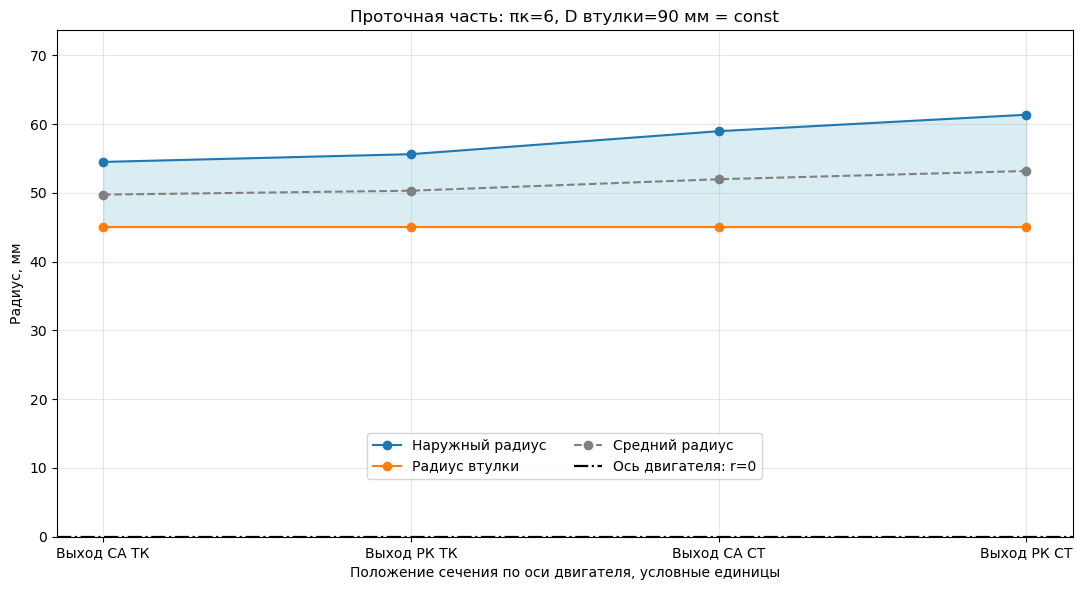

In [34]:
x_sections = np.array([0.0, 1.0, 2.0, 3.0])
section_names = ['Выход СА ТК', 'Выход РК ТК', 'Выход СА СТ', 'Выход РК СТ']

# Переводим средние диаметры и высоты из метров в миллиметры
D_sections = np.array([D1_tk, D2_tk, D1_st, D2_st]) * 1000
l_sections = np.array([l_stator_tk, l_rotor_tk, l_stator_st, l_rotor_st]) * 1000

# Три радиуса каждого сечения
r_mean = D_sections / 2
r_outer = (D_sections + l_sections) / 2
r_hub = (D_sections - l_sections) / 2

flowpath_sections = pd.DataFrame({
    'Сечение': section_names,
    'x, усл. ед.': x_sections,
    'Средний радиус, мм': r_mean,
    'Наружный радиус, мм': r_outer,
    'Радиус втулки, мм': r_hub,
    'Высота пера, мм': l_sections
})
display(flowpath_sections.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
ax.fill_between(x_sections, r_hub, r_outer, color='lightblue', alpha=0.45)
ax.plot(x_sections, r_outer, 'o-', label='Наружный радиус')
ax.plot(x_sections, r_hub, 'o-', label='Радиус втулки')
ax.plot(x_sections, r_mean, 'o--', color='gray', label='Средний радиус')

# y=0 — ось симметрии. Отрицательная половина не строится.
ax.axhline(0, color='black', linestyle='-.', linewidth=1.6, label='Ось двигателя: r=0')
ax.set_ylim(0, max(r_outer) * 1.20)
ax.set_xlim(-0.15, 3.15)
ax.set_xticks(x_sections)
ax.set_xticklabels(section_names)
ax.set_xlabel('Положение сечения по оси двигателя, условные единицы')
ax.set_ylabel('Радиус, мм')
ax.set_title(f'Проточная часть: πк={pi_k_design:g}, D втулки={D_hub*1000:g} мм = const')
ax.grid(alpha=0.3)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 0.10), ncol=2)
plt.tight_layout()
plt.show()
